# DDPG 직접 구현하기 — Pendulum-v1

> **Deep Deterministic Policy Gradient**: 연속 행동을 선택하는 Actor와 행동의 가치를 평가하는 Critic을 함께 학습한다.

이 노트북은 **개념 → Tensor Shape → 함수 → 학습 → 평가** 순서로 읽는다. 각 단계는 기능 단위로 분리했고, 설명은 필요한 부분에만 배치했다.

| 구성 | 역할 |
|---|---|
| Actor $\mu_\theta(s)$ | 상태를 보고 연속 행동을 출력 |
| Critic $Q_\phi(s,a)$ | 상태와 행동을 보고 행동 가치를 추정 |
| Replay Buffer | 이전 정책으로 수집한 경험도 다시 학습 |
| Target Network | TD 목표가 급격하게 바뀌지 않도록 갱신 |

**환경: Pendulum-v1**
- State: $(\cos\theta,\sin\theta,\dot\theta)$ — Shape (3,)
- Action: 연속적인 회전 토크 — Shape (1,), 범위 [-2, 2]
- Reward: 각도, 속도, 사용한 토크에 따른 보상. 일반적으로 음수이며 **0에 가까울수록 좋은 성적**이다.

일반 LunarLander-v3는 이산 행동 환경이므로, 연속 행동 DDPG 연습에는 Pendulum-v1이 더 적합하다.

## 1. 준비 — 라이브러리와 학습 설정

값을 한곳에 모아두면 실험하기 편하다. 작은 네트워크를 Step마다 업데이트하는 예제라 CPU를 기본으로 사용한다.

In [ ]:
import copy
import random
from collections import deque

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

# ── 재현성 ─────────────────────────────────────────
SEED = 42               
random.seed(SEED)       # 기본 라이브러리 random
np.random.seed(SEED)    # numpy 재현성
torch.manual_seed(SEED) # torch 재현성

DEVICE = torch.device(
  "cuda" if torch.cuda.is_available() else "cpu"
)

# ── 하이퍼파라미터 ───────────────────────────────────
EPISODES = 80           # 테스트 횟수
MAX_STEPS = 200         # 한 에피소드의 행동 횟수
BUFFER_SIZE = 100_000   # Reply Buffer 가용성
BATCH_SIZE = 128        # off policy 학습
RANDOM_STEPS = 1_000    # 초반 actor 대신 무작위 선택을 하는 횟수 (탐험)

GAMMA = 0.99
TAU = 0.005             # target network가 학습중인 신경망을 얼마나 빠르게 따라가는지       
ACTOR_LR = 1e-3        
CRITIC_LR = 1e-3        
NOISE_STD = 0.2  # Pendulum 토크의 절대 단위 (행동 노이즈)

print("device:", DEVICE)

device: cuda


## 2. 환경 확인 — 입력과 출력의 Shape

**Actor:** (B, 3) → (B, 1)

**Critic:** (B, 3) + (B, 1) → (B, 1)

B는 Batch 크기다. 먼저 실제 환경이 이 Shape을 가지는지 확인한다.

In [2]:
probe_env = gym.make("Pendulum-v1")
probe_env.action_space.seed(SEED)

OBS_DIM = int(np.prod(probe_env.observation_space.shape))
ACT_DIM = int(np.prod(probe_env.action_space.shape))
ACT_LOW = probe_env.action_space.low.astype(np.float32)
ACT_HIGH = probe_env.action_space.high.astype(np.float32)
ACT_LIMIT = float(ACT_HIGH[0])

# 본 튜토리얼의 Actor는 대칭 행동 범위를 가정한다.
assert np.allclose(ACT_LOW, -ACT_HIGH)

state, _ = probe_env.reset(seed=SEED)
print("state shape :", state.shape, "| example:", state)
print("action shape:", probe_env.action_space.shape)
print("action range:", ACT_LOW, "~", ACT_HIGH)

probe_env.close()

state shape : (3,) | example: [-0.14995256  0.9886932  -0.12224312]
action shape: (1,)
action range: [-2.] ~ [2.]


## 3. Actor — 행동을 직접 출력

A2C에서 행동별 확률 분포를 만들어 샘플링했던 것과 달리, DDPG Actor는 **행동 값 자체**를 반환한다.

$$
a = \mu_\theta(s)
$$

마지막 Tanh 출력 [-1, 1]에 ACT_LIMIT를 곱해 실제 토크 범위로 바꾼다.

In [3]:
class Actor(nn.Module):
    def __init__(self, obs_dim: int, act_dim: int, act_limit: float):
        super().__init__()
        self.act_limit = act_limit

        self.net = nn.Sequential(
            nn.Linear(obs_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, act_dim),
            nn.Tanh(),
        )

    def forward(self, states: torch.Tensor) -> torch.Tensor:
        # 입력: (B, obs_dim) → 출력: (B, act_dim)
        return self.net(states) * self.act_limit

## 4. Critic — Q(s, a)를 추정

DQN은 정해진 행동 각각의 Q값을 한꺼번에 출력한다. DDPG Critic은 **상태와 특정 연속 행동을 동시에 입력받아 Q값 하나**를 출력한다.

$$
Q_\phi(s,a) \in \mathbb{R}
$$

연결되는 Tensor Shape: (B, 3) + (B, 1) → (B, 4) → (B, 1)

In [ ]:
class Critic(nn.Module):
    def __init__(self, obs_dim: int, act_dim: int):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim + act_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 1),
        )

    def forward(
        self, states: torch.Tensor, actions: torch.Tensor
    ) -> torch.Tensor:
        # 마지막 차원에서 상태와 행동을 이어 붙인다.
        inputs = torch.cat([states, actions], dim=-1)
        return self.net(inputs)

### Shape 확인

학습 전에 입력과 출력을 직접 찍어본다. 여기서는 테스트용 Batch 크기 4를 사용한다.

In [5]:
actor = Actor(OBS_DIM, ACT_DIM, ACT_LIMIT).to(DEVICE)
critic = Critic(OBS_DIM, ACT_DIM).to(DEVICE)

example_states = torch.zeros((4, OBS_DIM), device=DEVICE)
example_actions = actor(example_states)
example_q = critic(example_states, example_actions)

assert example_actions.shape == (4, ACT_DIM)
assert example_q.shape == (4, 1)

print("state :", tuple(example_states.shape))
print("action:", tuple(example_actions.shape))
print("Q     :", tuple(example_q.shape))

state : (4, 3)
action: (4, 1)
Q     : (4, 1)


## 5. Replay Buffer — 과거 경험을 재사용

DDPG는 **Off-Policy** 알고리즘이다. 환경에서 얻은 경험 \((s,a,r,s',d)\)를 저장하고, 현재 정책이 아닌 **과거 정책으로 얻은 경험**도 다시 사용한다.

- states: (B, obs_dim)
- actions: (B, act_dim)
- rewards / terminated: (B, 1)
- next_states: (B, obs_dim)

여기서는 terminated와 truncated를 구분한다. 시간 제한에 의한 truncated는 미래 가치를 반드시 0으로 만들어야 한다는 뜻이 아니다.

In [ ]:
class ReplayBuffer:
    def __init__(self, capacity: int):
        self.memory = deque(maxlen=capacity)

    def add(self, state, action, reward, next_state, terminated):
        self.memory.append((
            np.array(state, dtype=np.float32, copy=True),
            np.array(action, dtype=np.float32, copy=True),
            float(reward),
            np.array(next_state, dtype=np.float32, copy=True),
            float(terminated),
        ))

    def sample(self, batch_size: int, device: torch.device):
        batch = random.sample(self.memory, batch_size)
        states, actions, rewards, next_states, terminated = zip(*batch)

        return (
            torch.as_tensor(np.stack(states), device=device),
            torch.as_tensor(np.stack(actions), device=device),
            torch.as_tensor(np.asarray(rewards, dtype=np.float32)[:, None], device=device),
            torch.as_tensor(np.stack(next_states), device=device),
            torch.as_tensor(np.asarray(terminated, dtype=np.float32)[:, None], device=device),
        )

    def __len__(self):
        return len(self.memory)


replay = ReplayBuffer(BUFFER_SIZE)

## 6. Target Network — 두 신경망을 천천히 따라가기

DDPG는 Actor와 Critic **각각에 Target Network를 둔다**. 매번 전체 파라미터를 덮어쓰지 않고 Soft Update한다.

$$
\theta_{\mathrm{target}}
\leftarrow (1-\tau)\theta_{\mathrm{target}}+\tau\theta
$$

TAU가 0.005라면 현재 가중치로 0.5%씩 이동한다.

In [7]:
actor_target = copy.deepcopy(actor)
critic_target = copy.deepcopy(critic)

# 타깃 신경망은 optimizer가 아니라 soft_update로만 갱신한다.
actor_target.requires_grad_(False)
critic_target.requires_grad_(False)

actor_optimizer = torch.optim.Adam(actor.parameters(), lr=ACTOR_LR)
critic_optimizer = torch.optim.Adam(critic.parameters(), lr=CRITIC_LR)


@torch.no_grad()
def soft_update(source: nn.Module, target: nn.Module, tau: float):
    for source_param, target_param in zip(
        source.parameters(), target.parameters()
    ):
        target_param.lerp_(source_param, tau)

## 7. DDPG 학습 함수 — Critic → Actor → Target

**① Critic**은 Bellman TD Target을 맞춘다.

$$
y=r+\gamma(1-d)Q_{\phi'}(s',\mu_{\theta'}(s'))
$$

$$
L_{\mathrm{critic}}=(Q_\phi(s,a)-y)^2
$$

**② Actor**는 Critic이 높은 가치를 평가하는 행동을 출력하도록 학습한다.

$$
L_{\mathrm{actor}}=-\mathbb{E}_s[Q_\phi(s,\mu_\theta(s))]
$$

특히 두 번째 식에서 기울기가 **Critic → Actor의 행동 출력 → Actor 가중치**로 전달되는 것을 살펴보자.

In [ ]:
def update_ddpg(buffer: ReplayBuffer) -> tuple[float, float]:
    states, actions, rewards, next_states, terminated = buffer.sample(
        BATCH_SIZE, DEVICE
    )

    # ── 1. Critic 업데이트 ─────────────────────────────────
    with torch.no_grad():
        next_actions = actor_target(next_states)          # (B, act_dim)
        next_q = critic_target(next_states, next_actions) # (B, 1)
        target_q = rewards + GAMMA * (1.0 - terminated) * next_q

    current_q = critic(states, actions)                    # (B, 1)
    critic_loss = F.mse_loss(current_q, target_q)

    critic_optimizer.zero_grad(set_to_none=True)
    critic_loss.backward()
    critic_optimizer.step()

    # ── 2. Actor 업데이트 ──────────────────────────────────
    # Critic의 파라미터는 고정하되, 행동에 대한 기울기는 전파한다.
    for parameter in critic.parameters():
        parameter.requires_grad_(False)

    predicted_actions = actor(states)                      # (B, act_dim)
    actor_loss = -critic(states, predicted_actions).mean()

    actor_optimizer.zero_grad(set_to_none=True)
    actor_loss.backward()
    actor_optimizer.step()

    for parameter in critic.parameters():
        parameter.requires_grad_(True)

    # ── 3. 타깃 네트워크를 조금씩 갱신 ─────────────────────
    soft_update(actor, actor_target, TAU)
    soft_update(critic, critic_target, TAU)

    return float(actor_loss.item()), float(critic_loss.item())

## 8. 환경에서 경험 수집하기

실제 환경에서 사용한 행동과 Actor가 원래 출력한 행동은 다를 수 있다.

$$
a_{\mathrm{env}}=\mathrm{clip}(\mu_\theta(s)+\epsilon,\ a_{\min},a_{\max})
$$

- **초기 RANDOM_STEPS:** 무작위 행동으로 경험을 먼저 모은다.
- **이후:** Actor 행동에 Gaussian Noise를 더해 탐험한다.
- **학습:** 현재 Step과 관계없이 Replay Buffer에서 무작위 Batch 추출.

탐험하면서 얻은 보상과 Noise 없는 정책 평가 보상은 다를 수 있다.

In [10]:
def train_ddpg(episodes: int = EPISODES) -> list[float]:
    env = gym.make("Pendulum-v1")
    env.action_space.seed(SEED)

    episode_rewards = []
    total_steps = 0

    for episode in range(1, episodes + 1):
        state, _ = env.reset(seed=SEED + episode)
        total_reward = 0.0

        for _ in range(MAX_STEPS):
            # ── 행동 선택: 초기에는 무작위, 이후에는 Actor + Noise ──
            if total_steps < RANDOM_STEPS:
                action = env.action_space.sample()
            else:
                with torch.no_grad():
                    state_tensor = torch.as_tensor(
                        state, dtype=torch.float32, device=DEVICE
                    ).unsqueeze(0)                            # (1, obs_dim)
                    action = actor(state_tensor).squeeze(0).cpu().numpy()

                action += np.random.normal(0.0, NOISE_STD, size=ACT_DIM)
                action = np.clip(action, ACT_LOW, ACT_HIGH).astype(np.float32)

            # ── 환경에서 전이와 보상 획득 ─────────────────────────
            next_state, reward, terminated, truncated, _ = env.step(action)
            replay.add(state, action, reward, next_state, terminated)

            if len(replay) >= BATCH_SIZE and total_steps >= RANDOM_STEPS:
                update_ddpg(replay)

            state = next_state
            total_reward += float(reward)
            total_steps += 1

            if terminated or truncated:
                break

        episode_rewards.append(total_reward)

        if episode % 10 == 0:
            recent_mean = np.mean(episode_rewards[-10:])
            print(
                f"episode {episode:3d}/{episodes} | "
                f"recent reward: {recent_mean:8.1f} | "
                f"buffer: {len(replay):5d}"
            )

    env.close()
    return episode_rewards

### 학습 실행

이 셀부터는 여러 차례 환경 Step과 역전파를 실행한다. 기본 EPISODES=80은 학습 과정을 관찰하기 위한 값이며, **좋은 성능을 보장하지 않는다**. 더 길게 학습하거나 Seed와 노이즈 설정을 비교해 볼 수 있다.

In [11]:
episode_rewards = train_ddpg()

episode  10/80 | recent reward:  -1342.2 | buffer:  2000
episode  20/80 | recent reward:   -883.8 | buffer:  4000
episode  30/80 | recent reward:   -219.1 | buffer:  6000
episode  40/80 | recent reward:   -142.8 | buffer:  8000
episode  50/80 | recent reward:   -149.0 | buffer: 10000
episode  60/80 | recent reward:   -155.3 | buffer: 12000
episode  70/80 | recent reward:   -189.4 | buffer: 14000
episode  80/80 | recent reward:   -180.4 | buffer: 16000


## 9. 학습 곡선

Pendulum 보상은 대체로 음수다. **0에 가까워지는 방향**이 개선이다. 에피소드별 보상과 최근 10개 이동평균을 함께 본다.

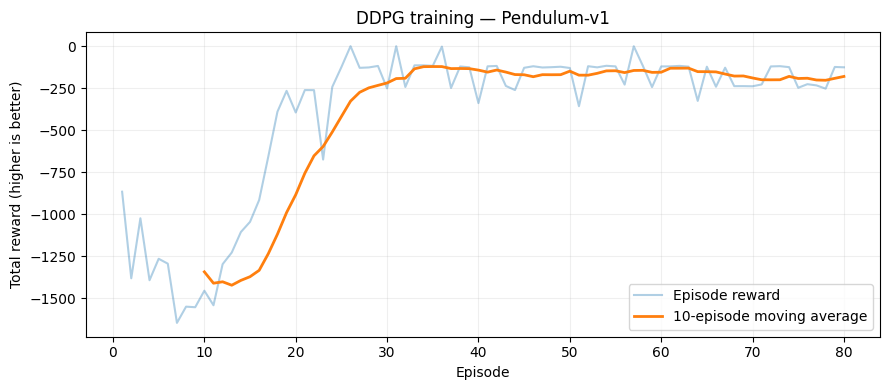

In [12]:
scores = np.asarray(episode_rewards, dtype=np.float32)
window = 10
moving_mean = np.convolve(scores, np.ones(window) / window, mode="valid")

plt.figure(figsize=(9, 4))
plt.plot(np.arange(1, len(scores) + 1), scores, alpha=0.35, label="Episode reward")
plt.plot(
    np.arange(window, len(scores) + 1),
    moving_mean,
    linewidth=2,
    label=f"{window}-episode moving average",
)
plt.title("DDPG training — Pendulum-v1")
plt.xlabel("Episode")
plt.ylabel("Total reward (higher is better)")
plt.grid(alpha=0.2)
plt.legend()
plt.tight_layout()
plt.show()

## 10. 평가 — Actor가 출력한 행동만 사용

학습에서는 탐험 노이즈를 넣었지만, 평가에서는 **노이즈 없이 결정적 행동만 실행**한다. 여러 번 실행하여 평균과 표준편차를 계산한다.

In [13]:
@torch.no_grad()
def evaluate_policy(episodes: int = 5) -> tuple[float, float]:
    env = gym.make("Pendulum-v1", render_mode="human")
    rewards_history = []

    actor.eval()
    for episode in range(episodes):
        state, _ = env.reset(seed=SEED + 10_000 + episode)
        total_reward = 0.0

        for _ in range(MAX_STEPS):
            state_tensor = torch.as_tensor(
                state, dtype=torch.float32, device=DEVICE
            ).unsqueeze(0)

            action = actor(state_tensor).squeeze(0).cpu().numpy()
            state, reward, terminated, truncated, _ = env.step(action)

            total_reward += float(reward)
            if terminated or truncated:
                break

        rewards_history.append(total_reward)

    actor.train()
    env.close()

    mean = float(np.mean(rewards_history))
    std = float(np.std(rewards_history))

    print(f"evaluation: mean={mean:.1f}, std={std:.1f} ({episodes} episodes)")
    return mean, std


eval_mean, eval_std = evaluate_policy()

evaluation: mean=-97.7, std=48.5 (5 episodes)


## 11. 정리 — DQN, 이전 Actor-Critic, DDPG

| | DQN | 이전에 구현한 Actor-Critic | DDPG |
|---|---|---|---|
| 행동 선택 | 최대 Q값의 행동 | Actor가 확률적으로 샘플링 | Actor가 연속 행동 출력 |
| 가치 평가 | Q-Network | 보통 V(s) | Q(s,a) |
| Actor 손실 | 별도 Actor 없음 | log_prob × Advantage 기반 | -Q(s, Actor(s)) |
| 학습 정책 | Off-Policy | On-Policy | Off-Policy |
| 경험 재사용 | Replay Buffer | 대체로 즉시 학습 | Replay Buffer |
| Target Network | Q 타깃 | 보통 사용 안 함 | Actor와 Critic 모두 |

**기억할 점**

1. **Model-Free**는 신경망이 없다는 뜻이 아니다. 환경의 상태 변화를 예측하는 모델을 별도로 학습하지 않는다는 뜻이다.
2. **Off-Policy**는 과거 또는 다른 정책이 모은 경험으로도 학습할 수 있다는 뜻이다.
3. **Deterministic Policy Gradient**는 Critic의 행동에 대한 기울기가 Actor까지 역전파된다는 뜻이다.

**추천 실험:** TAU, NOISE_STD, EPISODES를 하나씩 바꿔 보자. Space Z 같은 게임에 적용할 때는 조종이 연속값(추진력, 회전량)인지 먼저 확인해야 한다. 버튼형 이산 행동만 있다면 DDPG가 기본 선택지는 아니다.

논문: [Lillicrap et al., Continuous control with deep reinforcement learning](https://arxiv.org/abs/1509.02971)